In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import ast
from datasets import load_dataset

dataset = load_dataset("lukebarousse/data_jobs")
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else x)


In [7]:
# Count True and False values
work_from_home = df['job_work_from_home'].value_counts()

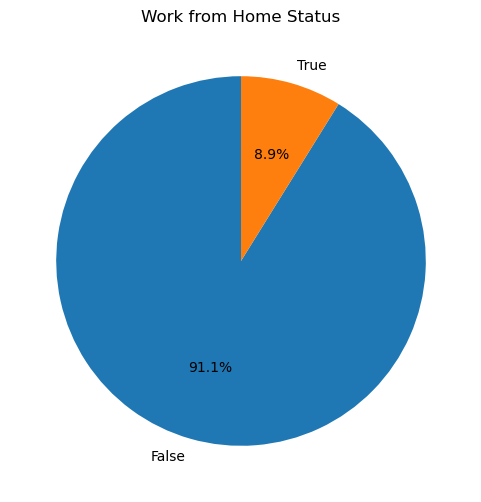

In [8]:
# Plotting the pie chart
plt.figure(figsize=(6,6))
plt.pie(work_from_home, labels=['False', 'True'], autopct='%1.1f%%', startangle=90)
plt.title('Work from Home Status')
plt.show()

In [9]:
# Count True and False values
job_no_degree = df['job_no_degree_mention'].value_counts()

In [10]:
job_health_insurance = df['job_health_insurance'].value_counts()

*** Let's plot these two DataFrames this along side our work_from_home using  subplot(). 

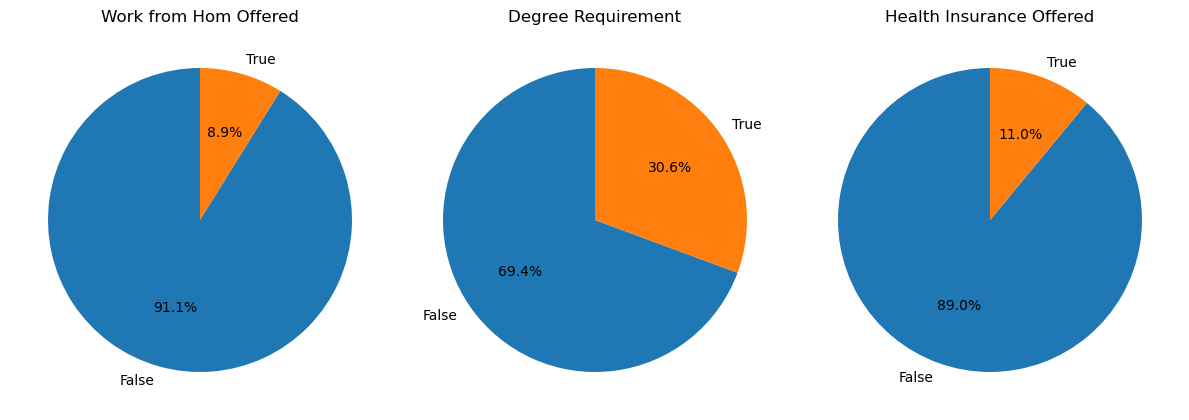

In [11]:
# Set up the matplotlib figure
fig, ax = plt.subplots(1, 3)
fig.set_size_inches((12, 5))

# Data Analyst Salaries
plt.subplot(1, 3, 1)
plt.pie(work_from_home, labels=['False', 'True'], autopct='%1.1f%%', startangle=90)
plt.title('Work from Hom Offered')

# Job No Degree
plt.subplot(1, 3, 2)
plt.pie(job_no_degree, labels=['False', 'True'], autopct='%1.1f%%', startangle=90)
plt.title('Degree Requirement')

# Job Health Insurance
plt.subplot(1, 3, 3)
plt.pie(job_health_insurance, labels=['False', 'True'], autopct='%1.1f%%', startangle=90)
plt.title('Health Insurance Offered')

plt.tight_layout()
plt.show()

*** Alternatively, you can use a for loop for this. 2. Let's plot these three DataFrames using a for loop.

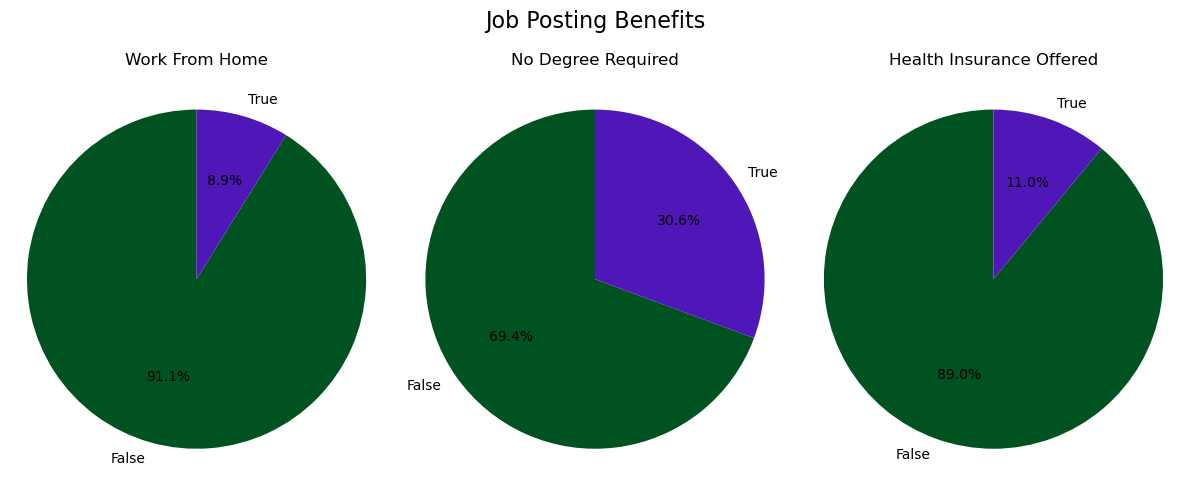

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(12, 5))

dict_columns = {
    'job_work_from_home': 'Work From Home',
    'job_no_degree_mention': 'No Degree Required',
    'job_health_insurance': 'Health Insurance Offered'
}

for i, (column, title) in enumerate(dict_columns.items()):
    counts = df[column].value_counts()
    ax[i].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, colors = ["#015221", "#4f17b8", "#ff076a"])
    ax[i].axis('equal')
    ax[i].set_title(title)
    
fig.suptitle('Job Posting Benefits', fontsize=16)
fig.tight_layout()

plt.show()